In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [3]:
df = pd.read_csv("../data/H2.csv")
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,...,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,...,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,...,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


In [4]:
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}\n")

Total Rows: 79330
Total Columns: 31



In [5]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  str    
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  str    
 12  Country                      79306 non-null  str    
 13  MarketSegment              

In [6]:
df.describe()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79326.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000,79330.000000
mean,0.417270,109.735724,2016.174285,27.177449,15.786625,0.795185,2.182957,1.850977,0.091370,0.004941,0.025615,0.079743,0.132371,0.187369,3.226774,105.304465,0.024367,0.546918
std,0.493111,110.948526,0.699181,13.398523,8.728451,0.885026,1.456416,0.509292,0.372177,0.084323,0.157983,0.415472,1.693411,0.608620,20.870890,43.602954,0.154919,0.780776
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,23.000000,2016.000000,17.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,79.200000,0.000000,0.000000
50%,0.000000,74.000000,2016.000000,27.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,99.900000,0.000000,0.000000
75%,1.000000,163.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,53.000000,31.000000,16.000000,41.000000,4.000000,3.000000,10.000000,1.000000,21.000000,72.000000,21.000000,391.000000,5400.000000,3.000000,5.000000


In [7]:
print((df.isna().sum()).sort_values(ascending=False))

Country                        24
Children                        4
IsCanceled                      0
ArrivalDateMonth                0
ArrivalDateWeekNumber           0
LeadTime                        0
ArrivalDateYear                 0
StaysInWeekendNights            0
ArrivalDateDayOfMonth           0
Adults                          0
StaysInWeekNights               0
Babies                          0
Meal                            0
MarketSegment                   0
DistributionChannel             0
IsRepeatedGuest                 0
PreviousCancellations           0
PreviousBookingsNotCanceled     0
ReservedRoomType                0
AssignedRoomType                0
BookingChanges                  0
DepositType                     0
Agent                           0
Company                         0
DaysInWaitingList               0
CustomerType                    0
ADR                             0
RequiredCarParkingSpaces        0
TotalOfSpecialRequests          0
ReservationSta

In [8]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct[missing_pct > 0])

Country     0.030253
Children    0.005042
dtype: float64


In [8]:
df.nunique()

IsCanceled                        2
LeadTime                        453
ArrivalDateYear                   3
ArrivalDateMonth                 12
ArrivalDateWeekNumber            53
ArrivalDateDayOfMonth            31
StaysInWeekendNights             14
StaysInWeekNights                29
Adults                            5
Children                          4
Babies                            5
Meal                              4
Country                         166
MarketSegment                     8
DistributionChannel               5
IsRepeatedGuest                   2
PreviousCancellations            10
PreviousBookingsNotCanceled      73
ReservedRoomType                  8
AssignedRoomType                  9
BookingChanges                   21
DepositType                       3
Agent                           224
Company                         208
DaysInWaitingList               115
CustomerType                      4
ADR                            5405
RequiredCarParkingSpaces    

In [13]:
df.select_dtypes(include='object').describe()

,ArrivalDateMonth,Meal,Country,MarketSegment,DistributionChannel,ReservedRoomType,AssignedRoomType,DepositType,Agent,Company,CustomerType,ReservationStatus,ReservationStatusDate
count,79330,79330,79306,79330,79330,79330,79330,79330,79330,79330,79330,79330,79330
unique,12,4,166,8,5,8,9,3,224,208,4,3,864
top,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,9,NULL,Transient,Check-Out,2015-10-21
freq,8983,62305,30960,38748,68945,62595,57007,66442,31955,75641,59404,46228,1416


In [16]:
obj_cols = df.select_dtypes(include='object').columns
for col in obj_cols:
    print(f"Column: {col}")
    print(df[col].unique())
    print("\n")

Column: ArrivalDateMonth
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']


Column: Meal
['HB       ' 'BB       ' 'SC       ' 'FB       ']


Column: Country
['PRT' 'ITA' 'ESP' 'DEU' 'FRA' 'NLD' 'GBR' 'ROU' 'BRA' 'SWE' 'AUT' 'AGO'
 'BEL' 'CHE' 'NOR' 'RUS' 'ISR' 'IRL' 'POL' 'CHN' 'USA' 'MAR' 'AUS' 'MOZ'
 'TUN' 'DNK' 'MEX' 'GRC' 'DZA' 'COL' 'LUX' 'CN' 'LVA' 'FIN' 'HRV' 'STP'
 'BGR' 'UKR' 'VEN' 'TWN' 'IRN' 'KOR' 'TUR' 'BLR' 'JPN' 'CZE' 'HUN' 'AZE'
 'KAZ' 'IND' 'NZL' 'IDN' 'LTU' 'LBN' 'SRB' 'SVN' 'SVK' 'MYS' 'CMR' 'CHL'
 'ARG' nan 'SGP' 'SEN' 'PER' 'EGY' 'SAU' 'KNA' 'JOR' 'ZAF' 'THA' 'KWT'
 'LKA' 'ALB' 'ETH' 'PHL' 'ARE' 'ECU' 'OMN' 'IRQ' 'AND' 'CPV' 'MUS' 'HND'
 'NGA' 'RWA' 'EST' 'PAK' 'GEO' 'GIB' 'ZMB' 'QAT' 'KHM' 'HKG' 'MCO' 'BGD'
 'ISL' 'UZB' 'URY' 'IMN' 'TJK' 'ARM' 'MDV' 'NIC' 'GGY' 'BEN' 'MAC' 'CYP'
 'VGB' 'MLT' 'CRI' 'TZA' 'JEY' 'GAB' 'MKD' 'BIH' 'VNM' 'GHA' 'TMP' 'GLP'
 'KEN' 'PRI' 'DOM' 'LIE' 'GNB' 'BHR' 'MNE' 'UMI' 'MY

In [19]:
obj_cols = df.select_dtypes(include='object').columns
for col in obj_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print("\n")

Column: ArrivalDateMonth
ArrivalDateMonth
August       8983
May          8232
July         8088
June         7894
October      7605
April        7480
September    7400
March        6458
February     4965
November     4357
December     4132
January      3736
Name: count, dtype: int64


Column: Meal
Meal
BB           62305
SC           10564
HB            6417
FB              44
Name: count, dtype: int64


Column: Country
Country
PRT    30960
FRA     8804
DEU     6084
GBR     5315
ESP     4611
       ...  
NCL        1
SDN        1
ATF        1
SLE        1
COM        1
Name: count, Length: 166, dtype: int64


Column: MarketSegment
MarketSegment
Online TA        38748
Offline TA/TO    16747
Groups           13975
Direct            6093
Corporate         2986
Complementary      542
Aviation           237
Undefined            2
Name: count, dtype: int64


Column: DistributionChannel
DistributionChannel
TA/TO        68945
Direct        6780
Corporate     3408
GDS            193
Undefined   

In [52]:
num_cols = df.select_dtypes(include='number').columns
for col in num_cols:
    print(f"Column: {col}")
    print(df[col].unique())
    print("\n")

Column: IsCanceled
[0 1]


Column: LeadTime
[  6  88  65  92 100  79   3  63  62  43   4  97  80  60 106  68  18  71
  85  75  89  83  72 111  86  73  55  69  76  61  77  54  90 117 105  51
  24  84 115  67  87 109  96 114  66  59 122 123  94 120   0 125  82 107
 103  12 118 108 119  20  22  99 112  93 132 110   2  15  98 124  16  19
  81   5  27  25 126  74   1  64 138 102  78 130 135   7  28  34 141  33
 101  13  11  36 128  30 145 142  39 121 147 140 104  41 134 150   8 133
  10  40 131   9 137 127  46  47  14 151  17  44 113  53  50 162 148 149
  21  23  37  49  26  32  52 173  45 164  42  58  48 168  31  38 175 170
  29  35 167 166  56 152 155 116  95  57 179  70 192 169 193 199 204 200
  91 198 158 210 156 174 184 180 195 216 233 212 139 242 208 146 144 159
 197 129 160 154 393 251 157 161 136 182 267 274 268 190 281 188 275 270
 265 288 143 295 443 194 437 253 207 302 259 178 289 298 286 309 196 273
 276 297 191 451 217 323 316 189 322 211 163 172 153 205 202 330 177 220
 247 21

In [53]:
for col in num_cols:
    print(f"Column: {col}")
    print(df[col].value_counts())
    print("\n")

Column: IsCanceled
IsCanceled
0    46228
1    33102
Name: count, dtype: int64


Column: LeadTime
LeadTime
0      3109
1      1865
2      1130
4      1052
3      1022
       ... 
389       1
387       1
366       1
380       1
463       1
Name: count, Length: 453, dtype: int64


Column: ArrivalDateYear
ArrivalDateYear
2016    38140
2017    27508
2015    13682
Name: count, dtype: int64


Column: ArrivalDateWeekNumber
ArrivalDateWeekNumber
33    2383
42    2032
20    2016
30    2011
32    1991
17    1965
25    1959
34    1950
21    1948
18    1914
38    1887
23    1869
28    1865
27    1854
41    1842
39    1833
24    1823
15    1783
29    1726
40    1722
22    1697
26    1670
16    1650
35    1642
19    1640
31    1640
13    1605
37    1596
44    1546
14    1525
8     1497
43    1435
12    1427
10    1422
36    1411
11    1391
9     1322
45    1251
7     1205
53    1198
49    1066
46    1060
50    1056
48    1011
47     977
4      968
5      886
6      826
3      766
2      761
1      70

Matplotlib is building the font cache; this may take a moment.


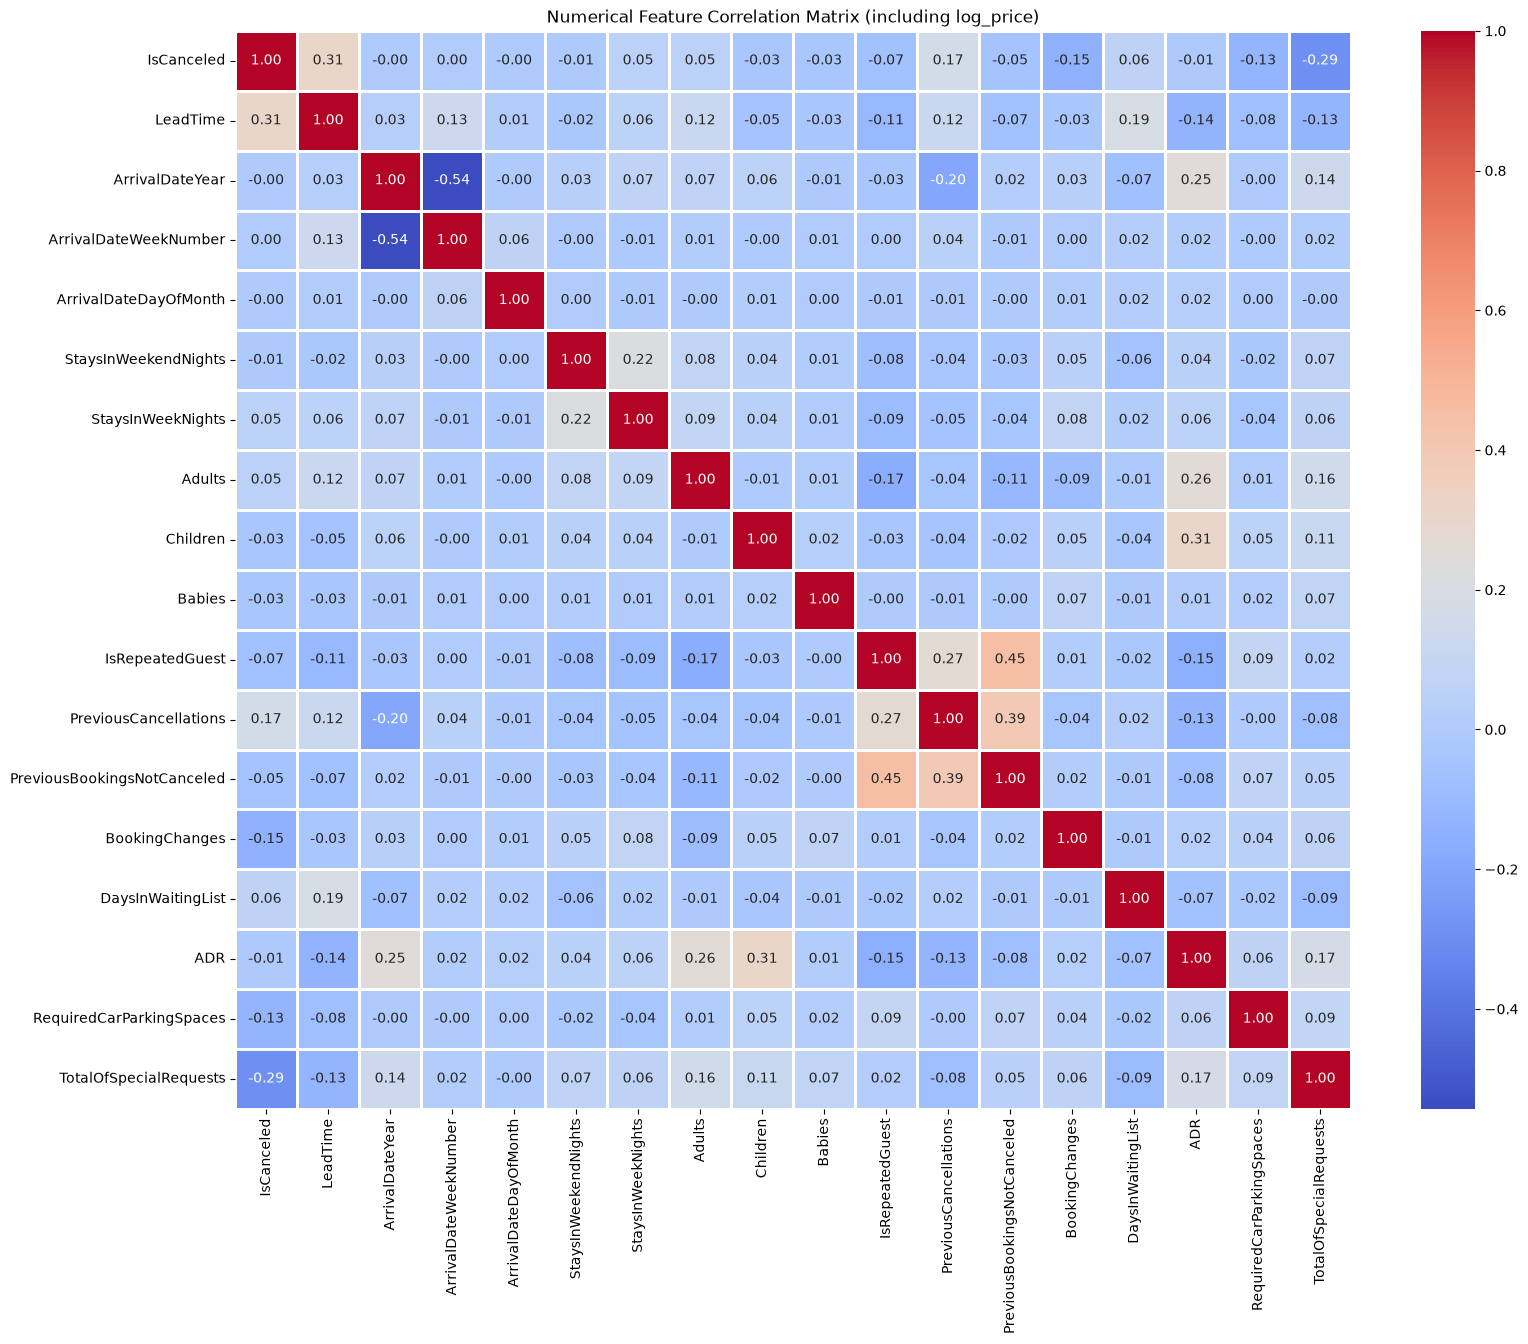

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True),annot=True, fmt=".2f", cmap="coolwarm",linewidths=0.8)
plt.title("Numerical Feature Correlation Matrix (including log_price)")
plt.show()

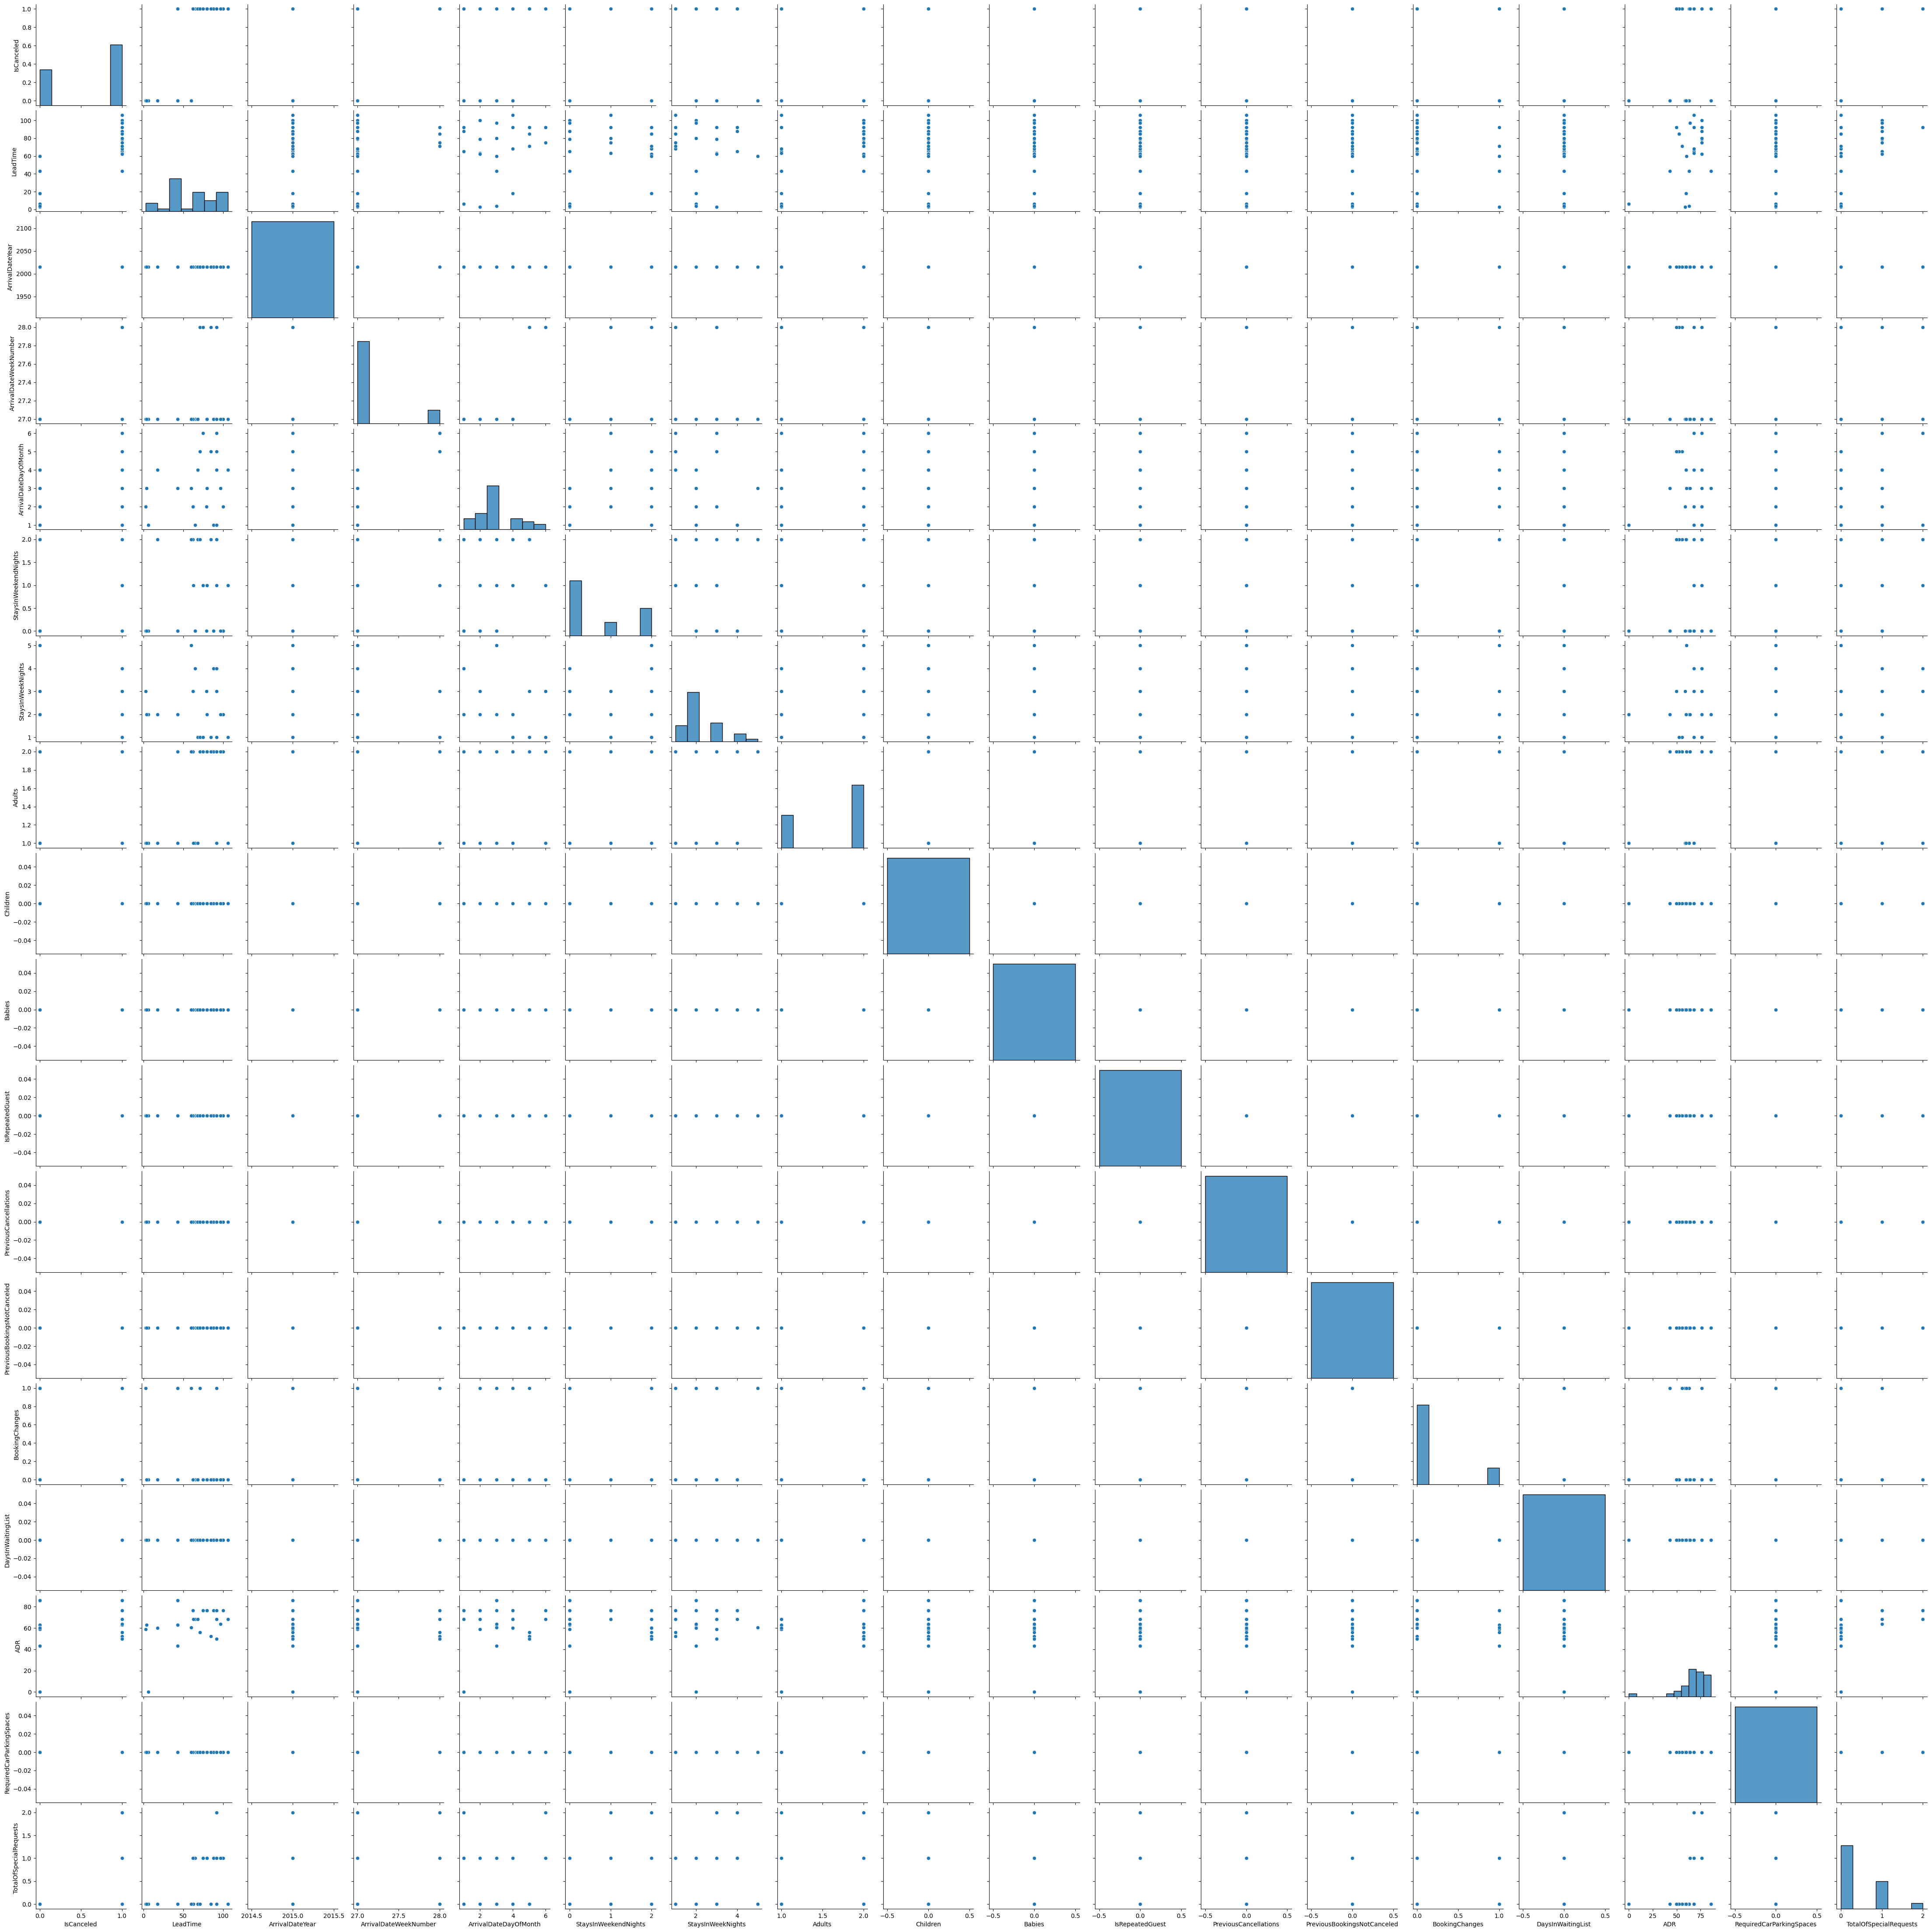

In [39]:
sns.pairplot(df[:35])

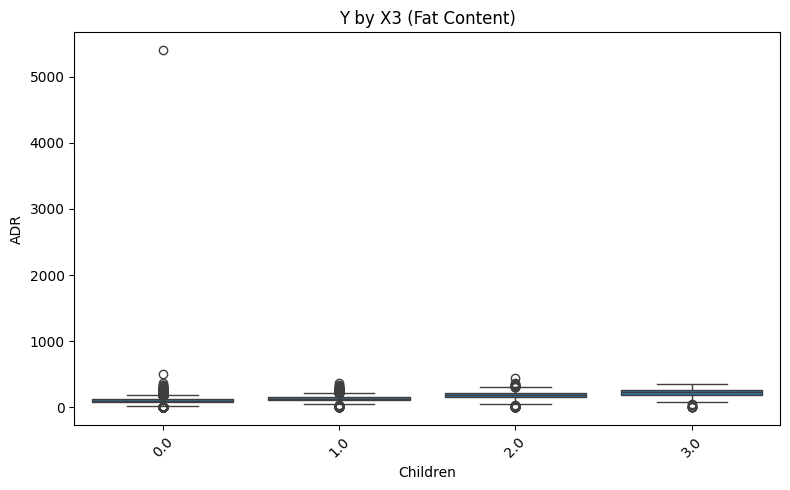

            mean  median    std  count
Children                              
0.0       102.10    98.0  40.85  74220
1.0       132.24   128.0  40.70   3023
2.0       179.88   185.0  57.10   2024
3.0       208.70   238.4  94.40     59


In [41]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Children'], y=df['ADR'])
plt.title('Y by X3 (Fat Content)')
plt.xlabel('Children')
plt.ylabel('ADR')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df.groupby('Children')['ADR'].agg(['mean', 'median', 'std', 'count']).round(2))

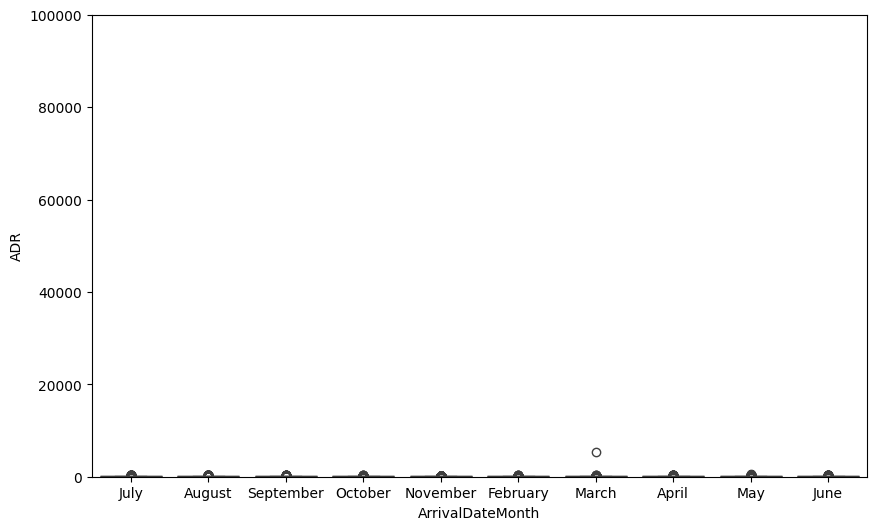

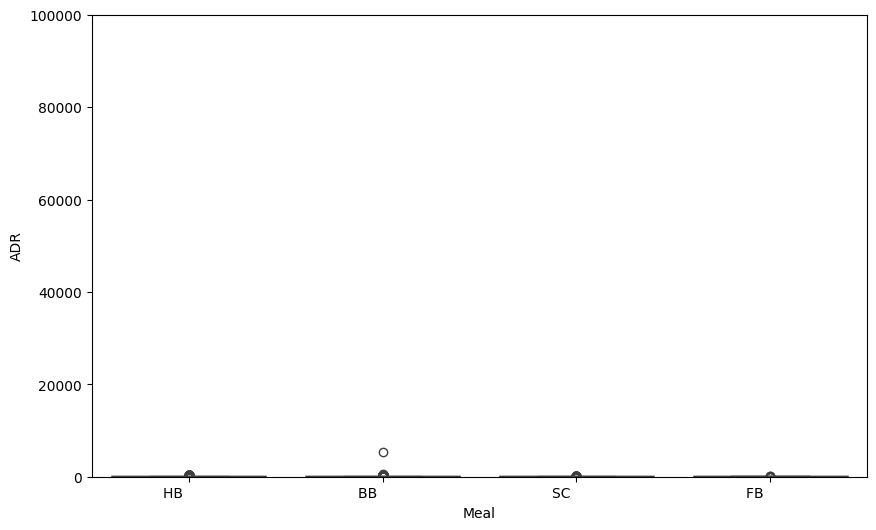

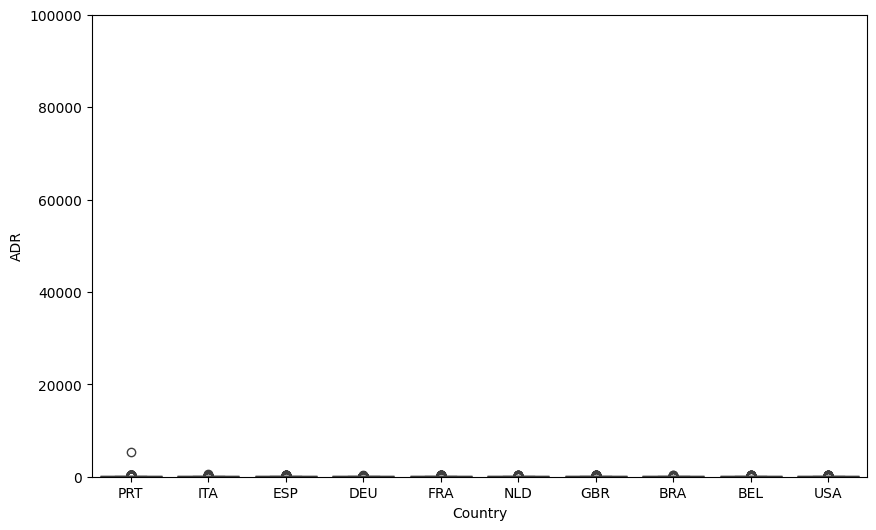

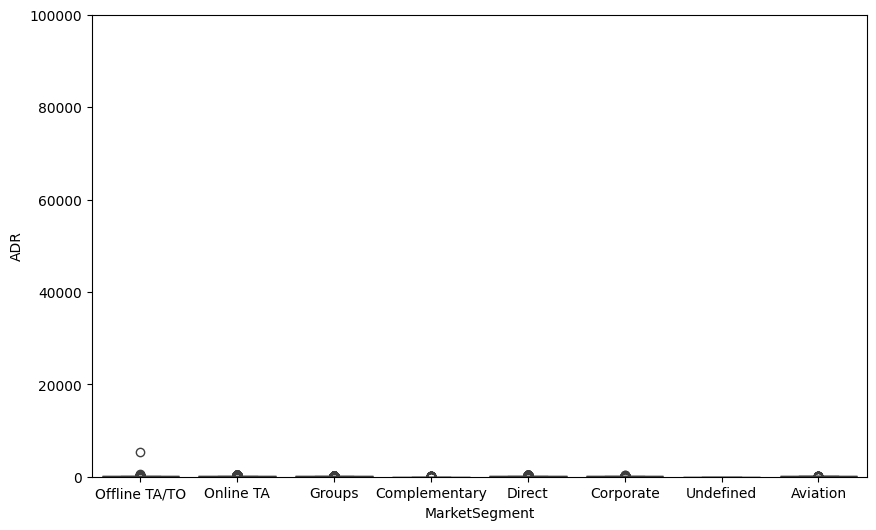

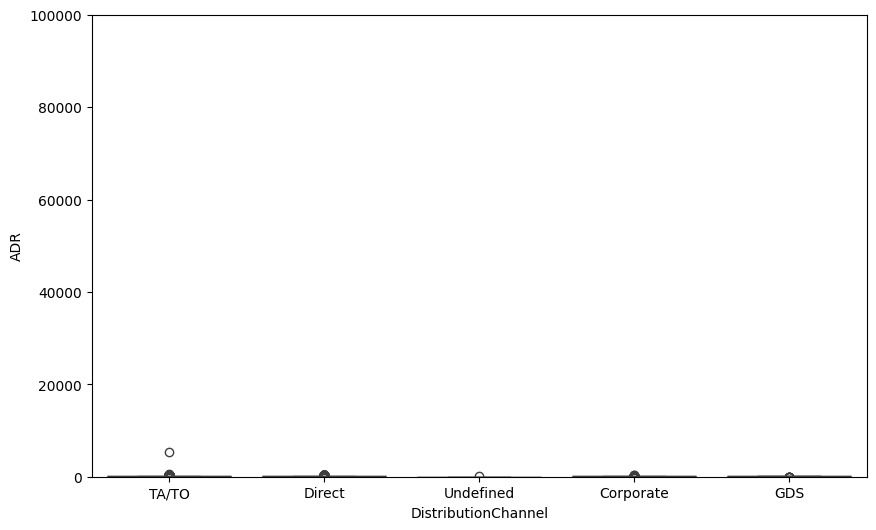

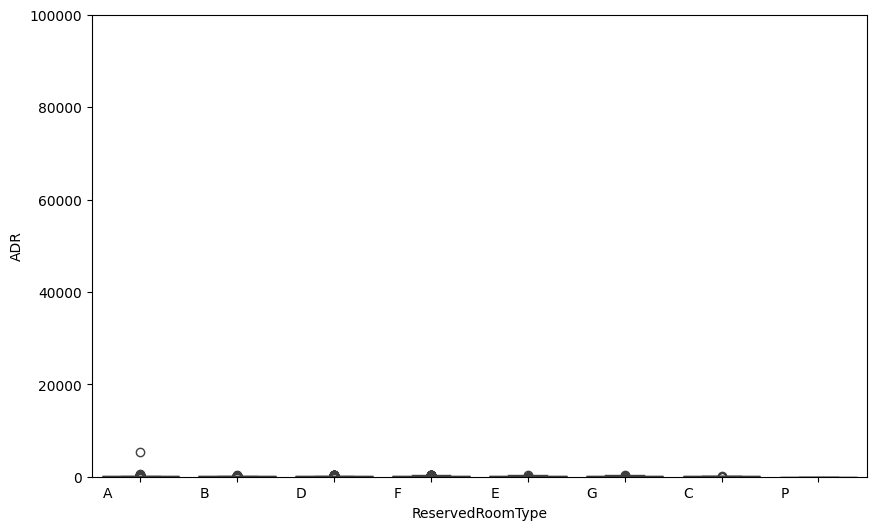

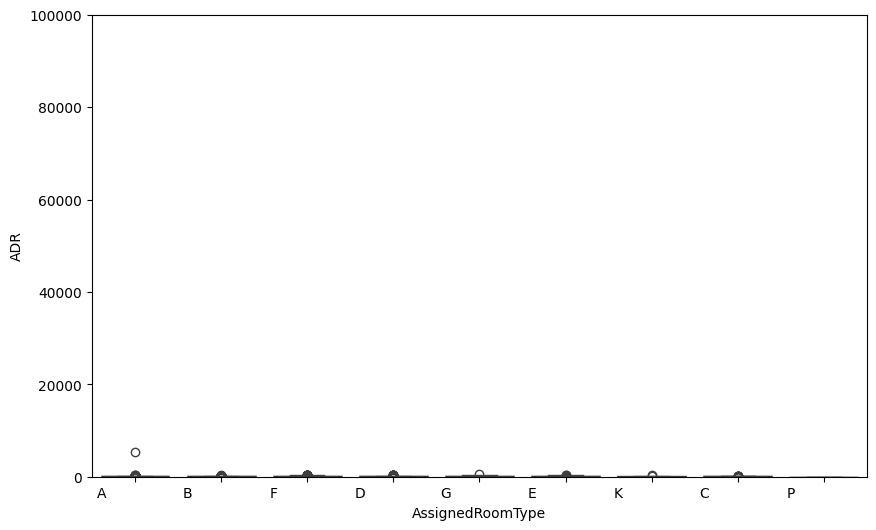

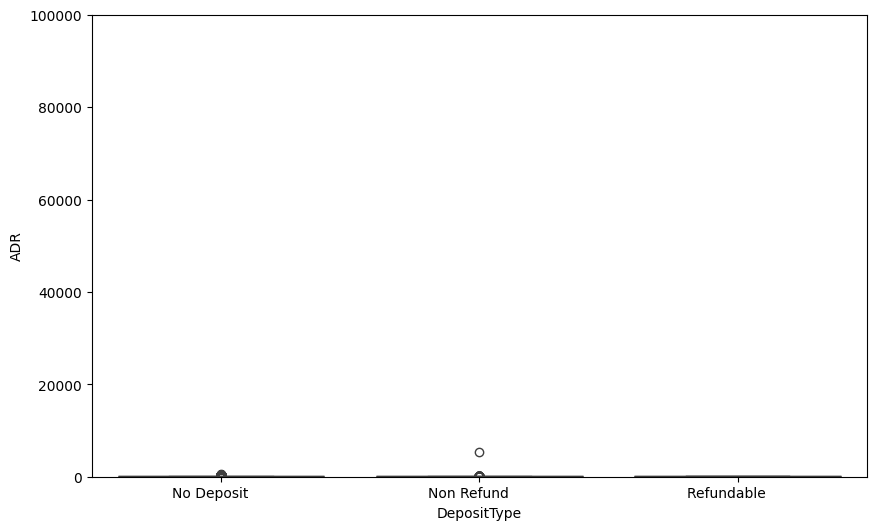

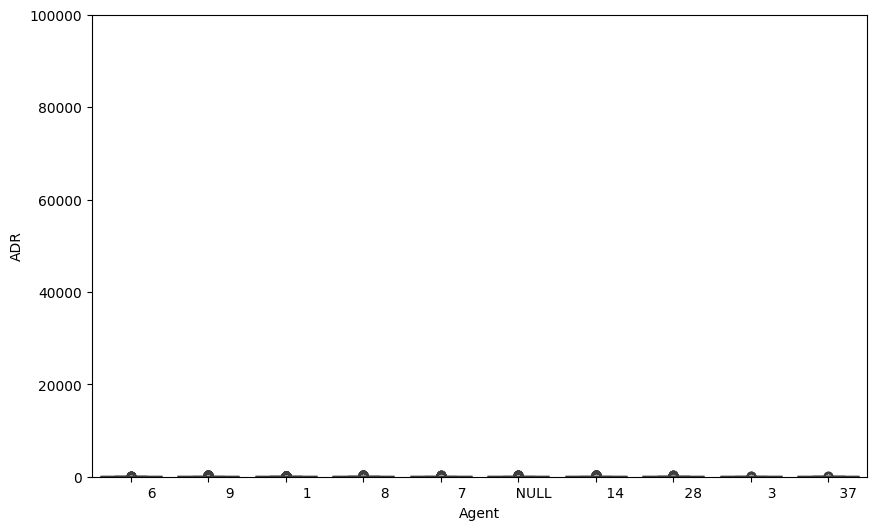

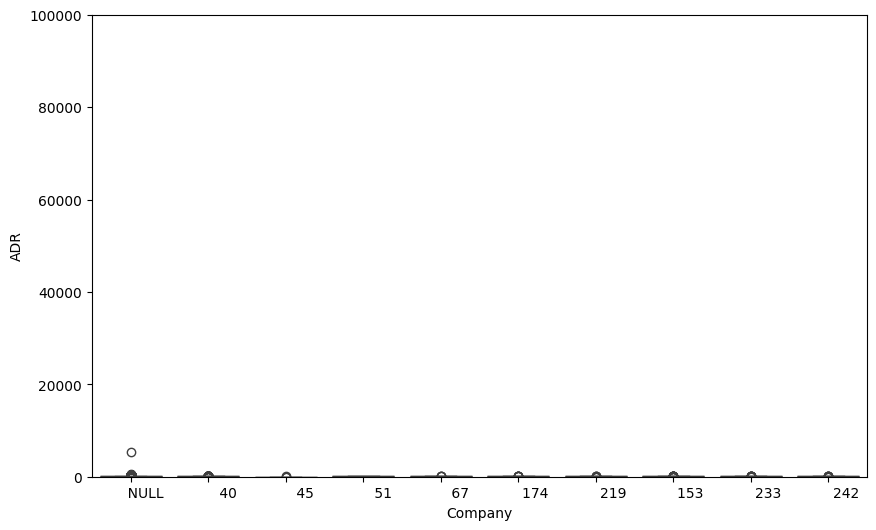

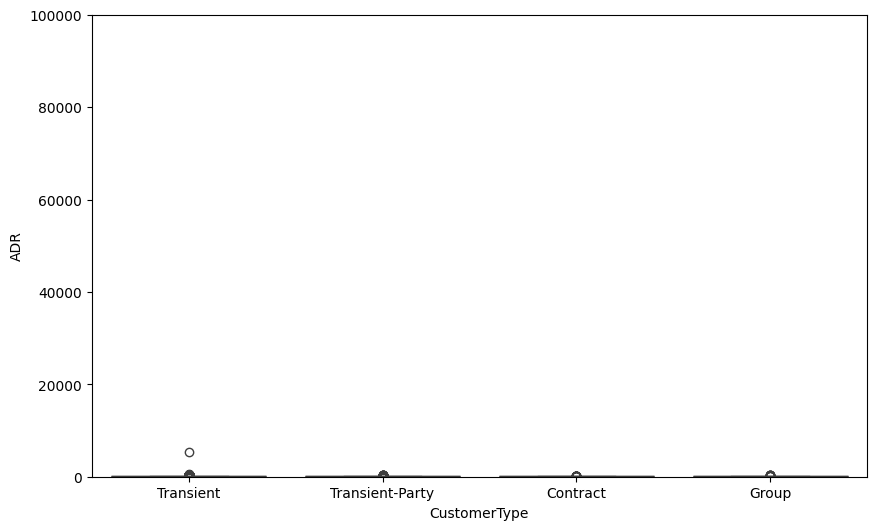

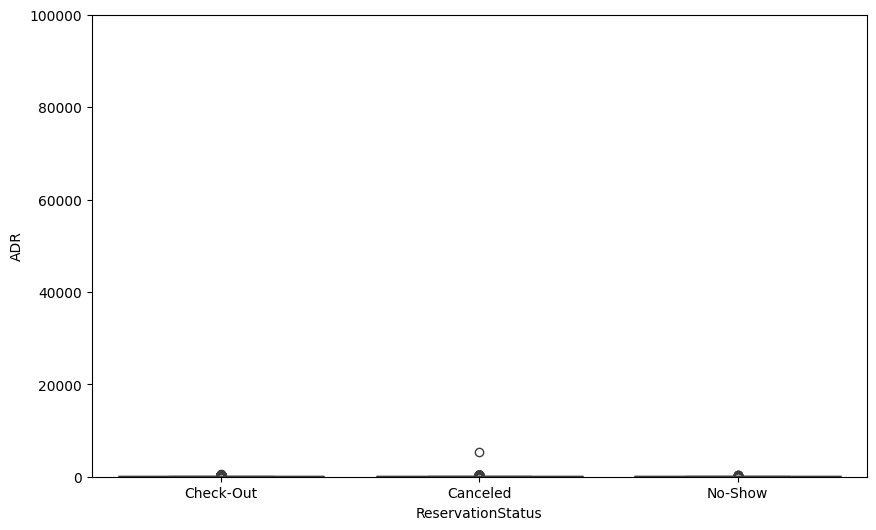

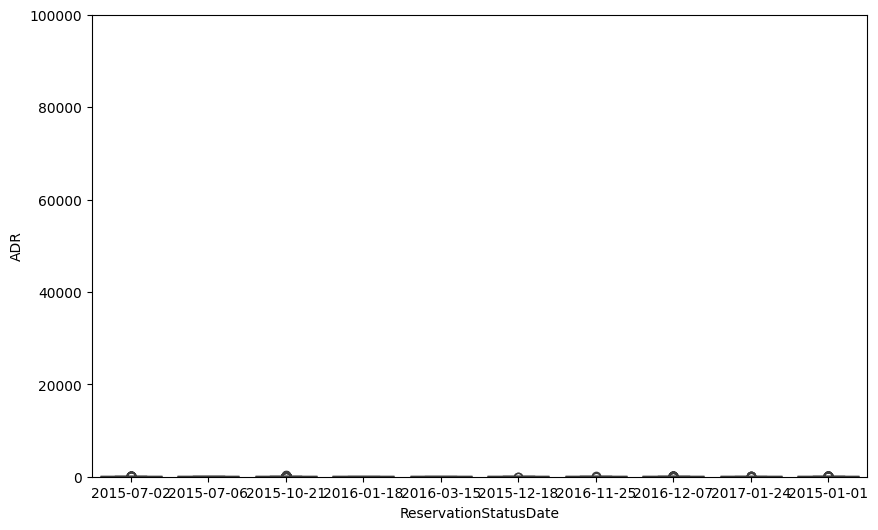

In [42]:
for col in df.select_dtypes('object').columns:
   top = df[col].value_counts().index[:10]
   filtereddata = df[df[col].isin(top)]
   plt.figure(figsize=(10,6))
   sns.boxplot(x=col,y='ADR',data=filtereddata)
   plt.ylim(0, 100000)
   plt.show()

In [54]:
num_cols = df.select_dtypes(include='number')
for c in num_cols.columns:
    Q1 = num_cols[c].quantile(0.25)
    Q3 = num_cols[c].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    outliers = ((num_cols[c]<lower)|(num_cols[c]>upper)).sum()
    #outliers = num_cols[c][(num_cols[c]<lower)|(num_cols[c]>upper)]
    print(f"outliers in {c}:")
    print(outliers)
    print()

outliers in IsCanceled:
0

outliers in LeadTime:
2576

outliers in ArrivalDateYear:
0

outliers in ArrivalDateWeekNumber:
0

outliers in ArrivalDateDayOfMonth:
0

outliers in StaysInWeekendNights:
82

outliers in StaysInWeekNights:
719

outliers in Adults:
21075

outliers in Children:
5106

outliers in Babies:
369

outliers in IsRepeatedGuest:
2032

outliers in PreviousCancellations:
5389

outliers in PreviousBookingsNotCanceled:
1588

outliers in BookingChanges:
10268

outliers in DaysInWaitingList:
3443

outliers in ADR:
3387

outliers in RequiredCarParkingSpaces:
1926

outliers in TotalOfSpecialRequests:
1811



In [56]:
for c in num_cols.columns:
    Q1 = num_cols[c].quantile(0.25)
    Q3 = num_cols[c].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR   
    outliers = num_cols[c][(num_cols[c]<lower)|(num_cols[c]>upper)]
    print(f"outliers in {c}:")
    print(outliers.value_counts())
    print()

outliers in IsCanceled:
Series([], Name: count, dtype: int64)

outliers in LeadTime:
LeadTime
405    129
386    111
423    108
414    105
377     89
      ... 
387      1
389      1
458      1
380      1
463      1
Name: count, Length: 83, dtype: int64

outliers in ArrivalDateYear:
Series([], Name: count, dtype: int64)

outliers in ArrivalDateWeekNumber:
Series([], Name: count, dtype: int64)

outliers in ArrivalDateDayOfMonth:
Series([], Name: count, dtype: int64)

outliers in StaysInWeekendNights:
StaysInWeekendNights
6     40
8     24
9      6
7      6
14     2
10     2
16     1
13     1
Name: count, dtype: int64

outliers in StaysInWeekNights:
StaysInWeekNights
7     201
8     160
10    145
9      73
11     26
12     20
15     18
14     12
20     10
13     10
16      9
21      8
22      6
18      6
19      5
17      3
24      2
34      1
35      1
41      1
25      1
30      1
Name: count, dtype: int64

outliers in Adults:
Adults
1    15879
3     4775
0      390
4       31
Name: cou